# NMT Anh -> Việt - seq2seq

## 1. Cấu hình

In [8]:
MODEL = "seq2seq"
MODE = "new"
RUN_NAME = ""
TOTAL_EPOCHS = 30
USE_AMP = True
RUN_FINAL_EVALUATION = True
OTHER_RUN_NAME = "transformer_20261110_174642"

## 2. Nạp project và cài thư viện

In [2]:
import io
import os
import sys
import subprocess
import zipfile
from pathlib import Path
from google.colab import files

PROJECT = Path('/content/nmt-en-vi')
uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError('Chọn đúng một file nmt_en_vi_project.zip mới.')
with zipfile.ZipFile(io.BytesIO(next(iter(uploaded.values())))) as archive:
    required = 'nmt-en-vi/scripts/resume_optimized.py'
    if required not in archive.namelist():
        raise ValueError('ZIP này chưa có bản tối ưu; hãy chọn ZIP mới.')
    for info in archive.infolist():
        parts = Path(info.filename).parts
        if info.is_dir() or not parts or parts[0] != 'nmt-en-vi':
            continue
        if '..' in parts:
            raise ValueError('Đường dẫn ZIP không hợp lệ.')
        relative = Path(*parts[1:])
        if relative.parts[0] == 'runs':
            continue
        destination = PROJECT / relative
        if relative.parts[0] in ('data', 'tokenizers', 'artifacts') and destination.exists():
            continue
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(archive.read(info))
del uploaded
os.chdir(PROJECT)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                'requirements-dev.txt'], check=True)


def run(*arguments):
    command = [sys.executable, '-u', *map(str, arguments)]
    process = subprocess.Popen(command, cwd=PROJECT, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, bufsize=1)
    try:
        for line in process.stdout:
            print(line, end='', flush=True)
        result = process.wait()
        if result:
            raise subprocess.CalledProcessError(result, command)
    finally:
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=15)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        process.stdout.close()

Saving nmt_en_vi_project.zip to nmt_en_vi_project.zip


## 3. Kết nối Drive và kiểm tra checkpoint

In [3]:
import gc
import torch
from datetime import datetime
from google.colab import drive

drive.mount('/content/drive')
if not torch.cuda.is_available():
    raise RuntimeError('Hãy chọn runtime GPU rồi chạy lại notebook.')
print('PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0))
RUN_ROOT = Path('/content/drive/MyDrive/nmt_runs')
RUN_ROOT.mkdir(parents=True, exist_ok=True)
if MODE not in ('new', 'resume'):
    raise ValueError("MODE phải là 'new' hoặc 'resume'.")
if TOTAL_EPOCHS < 1:
    raise ValueError('TOTAL_EPOCHS phải dương.')
if not RUN_NAME:
    if MODE == 'resume':
        raise ValueError('Điền RUN_NAME chính xác để resume.')
    RUN_NAME = MODEL + '_' + datetime.now().strftime('%Y%m%d_%H%M%S')
if Path(RUN_NAME).name != RUN_NAME:
    raise ValueError('RUN_NAME chỉ là tên thư mục, không phải đường dẫn.')
RUN_DIR = RUN_ROOT / RUN_NAME
COMPLETED_EPOCH = 0
if MODE == 'resume':
    checkpoint = torch.load(RUN_DIR / 'last.pt', map_location='cpu', weights_only=False)
    if checkpoint['config']['model'] != MODEL:
        raise ValueError('Checkpoint thuộc mô hình khác.')
    COMPLETED_EPOCH = checkpoint['epoch']
    print('Epoch đã lưu:', COMPLETED_EPOCH)
    print('AMP trước đó:', checkpoint['config']['amp'])
    del checkpoint
    gc.collect()
elif RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    raise FileExistsError('Run đã có dữ liệu. Chọn MODE=resume hoặc đổi RUN_NAME.')
print('Thư mục chạy:', RUN_DIR)
print('Epoch mục tiêu:', TOTAL_EPOCHS)

Mounted at /content/drive
PyTorch: 2.14.1+cu130
GPU: Tesla T4
Thư mục chạy: /content/drive/MyDrive/nmt_runs/seq2seq_20261110_194635
Epoch mục tiêu: 30


## 4. Chuẩn bị và kiểm thử

In [4]:
CHECKS_PASSED = False
if MODE == 'new':
    run('scripts/prepare.py')
run('-m', 'pytest', '-q', 'tests')
CHECKS_PASSED = True

{
  "max_len_train_including_special_tokens": 100,
  "vocabulary_sizes": {
    "en": 8000,
    "vi": 8000
  },
  "splits": {
    "train": {
      "raw_pairs": 133317,
      "used_pairs": 132009,
      "dropped": 1308,
      "empty_source": 149,
      "empty_target": 112,
      "en": {
        "mean_subwords": 24.776712647299295,
        "p95_subwords": 58.0,
        "max_subwords": 815,
        "sha256": "c26dfeed74b6bf3752f5ca552f2412456f0de153f7c804df8717931fb3a5c78a"
      },
      "vi": {
        "mean_subwords": 25.721205847716345,
        "p95_subwords": 61.0,
        "max_subwords": 861,
        "sha256": "707206edf2dc0280273952c7b70544ea8a1363aa69aaeb9d70514b888dc3067d"
      },
      "duplicate_pairs_within_split": 1145
    },
    "dev": {
      "raw_pairs": 1553,
      "used_pairs": 1553,
      "dropped": 0,
      "empty_source": 0,
      "empty_target": 0,
      "en": {
        "mean_subwords": 21.72826786864134,
        "p95_subwords": 48.0,
        "max_subwords": 108,
   

## 5. Huấn luyện hoặc tiếp tục

In [5]:
if not CHECKS_PASSED:
    raise RuntimeError('Chạy thành công bước kiểm thử trước.')
precision_flag = '--amp' if USE_AMP else '--no-amp'
if MODE == 'resume':
    if COMPLETED_EPOCH >= TOTAL_EPOCHS:
        print('Checkpoint đã đạt epoch mục tiêu. Không train lại.')
    else:
        run('scripts/resume_optimized.py', '--run-dir', RUN_DIR,
            '--epochs', TOTAL_EPOCHS, precision_flag)
else:
    run('translate_seq2seq/train.py', '--output-dir', RUN_DIR,
        '--epochs', TOTAL_EPOCHS, precision_flag)


>>> Epoch 1/30 | amp=True
  train 100/1121 | NLL=6.6007 | elapsed=24s | train ETA=245s | skipped=0
  train 200/1121 | NLL=6.4211 | elapsed=45s | train ETA=209s | skipped=0
  train 300/1121 | NLL=6.2631 | elapsed=68s | train ETA=187s | skipped=0
  train 400/1121 | NLL=6.1045 | elapsed=91s | train ETA=164s | skipped=0
  train 500/1121 | NLL=5.9476 | elapsed=113s | train ETA=140s | skipped=0
  train 600/1121 | NLL=5.8077 | elapsed=135s | train ETA=117s | skipped=0
  train 700/1121 | NLL=5.6832 | elapsed=157s | train ETA=94s | skipped=0
  train 800/1121 | NLL=5.5769 | elapsed=181s | train ETA=72s | skipped=0
  train 900/1121 | NLL=5.4791 | elapsed=202s | train ETA=50s | skipped=0
  train 1000/1121 | NLL=5.3911 | elapsed=224s | train ETA=27s | skipped=0
  train 1100/1121 | NLL=5.3024 | elapsed=245s | train ETA=5s | skipped=0
  train 1121/1121 | NLL=5.2859 | elapsed=250s | train ETA=0s | skipped=0
Train done: 249.7s. Computing dev NLL...
Computing dev BLEU (greedy, FP32)...
epoch=1 train_nl

## 6. Xem lịch sử và thời gian thực tế

Epoch cuối đã lưu: 15
Epoch 11: train=4.29 phút | tổng=4.35 phút | dev BLEU=24.04 | AMP=True
Epoch 12: train=4.23 phút | tổng=4.28 phút | dev BLEU=23.88 | AMP=True
Epoch 13: train=4.29 phút | tổng=4.34 phút | dev BLEU=23.14 | AMP=True
Epoch 14: train=4.24 phút | tổng=4.32 phút | dev BLEU=23.64 | AMP=True
Epoch 15: train=4.24 phút | tổng=4.29 phút | dev BLEU=23.66 | AMP=True


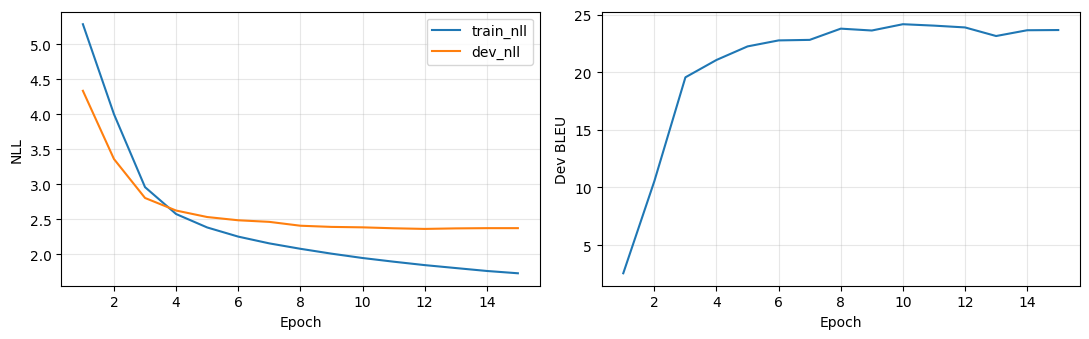

In [6]:
import csv
import matplotlib.pyplot as plt

with (RUN_DIR / 'history.csv').open() as stream:
    history = list(csv.DictReader(stream))
if not history:
    raise RuntimeError('Chưa có epoch hoàn chỉnh.')
print('Epoch cuối đã lưu:', history[-1]['epoch'])
for row in history[-5:]:
    print(f"Epoch {row['epoch']}: train={float(row['train_seconds']) / 60:.2f} phút | "
          f"tổng={float(row['epoch_seconds_including_dev']) / 60:.2f} phút | "
          f"dev BLEU={float(row['dev_bleu']):.2f} | AMP={row.get('amp', '?')}")
epochs = [int(row['epoch']) for row in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for metric in ('train_nll', 'dev_nll'):
    axes[0].plot(epochs, [float(row[metric]) for row in history], label=metric)
axes[0].legend()
axes[0].set_ylabel('NLL')
axes[1].plot(epochs, [float(row['dev_bleu']) for row in history])
axes[1].set_ylabel('Dev BLEU')
for axis in axes:
    axis.set_xlabel('Epoch')
    axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Đánh giá cuối và so sánh


In [9]:
import json

if RUN_FINAL_EVALUATION:
    run('evaluate.py', '--run-dir', RUN_DIR, '--data-dir',
        PROJECT / 'data/iwslt15_en_vi', '--beam', 1, 5, '--show', 8)
    metrics = json.loads((RUN_DIR / 'evaluation/test/metrics.json').read_text())
    print(json.dumps(metrics['results'], ensure_ascii=False, indent=2))
    if OTHER_RUN_NAME:
        other = RUN_ROOT / OTHER_RUN_NAME
        if not (other / 'evaluation/test/metrics.json').exists():
            raise FileNotFoundError('Mô hình còn lại chưa có kết quả test.')
        run('compare.py', '--runs', RUN_DIR, other,
            '--output-dir', RUN_ROOT / 'comparison', '--plots')
else:
    print('Chưa chạy test. Tiếp tục theo dõi dev trước khi chốt mô hình.')

greedy: BLEU=26.83, chrF2=46.05
{"index": 0, "source": "When I was little , I thought my country was the best on the planet , and I grew up singing a song called &quot; Nothing To Envy . &quot;", "reference": "Khi tôi còn nhỏ , Tôi nghĩ rằng BắcTriều Tiên là đất nước tốt nhất trên thế giới và tôi thường hát bài &quot; Chúng ta chẳng có gì phải ghen tị . &quot;", "prediction": "Khi tôi còn nhỏ , tôi nghĩ đất nước mình là người tốt nhất hành tinh , và tôi đã lớn lên một bài hát tên là &quot; Không có Envy &quot; ."}
{"index": 1, "source": "And I was very proud .", "reference": "Tôi đã rất tự hào về đất nước tôi .", "prediction": "Và tôi rất tự hào ."}
{"index": 2, "source": "In school , we spent a lot of time studying the history of Kim Il-Sung , but we never learned much about the outside world , except that America , South Korea , Japan are the enemies .", "reference": "Ở trường , chúng tôi dành rất nhiều thời gian để học về cuộc đời của chủ tịch Kim II- Sung , nhưng lại không học nhiề